In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import scrublet as scr
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rcParams
from matplotlib import rc
from matplotlib import colors
import seaborn as sb
from collections import Counter
import glob

sc.settings.set_figure_params(dpi = 160, color_map = 'RdPu', dpi_save = 300, format = 'pdf')
plt.rcParams["figure.figsize"] = [6,6]

In [2]:
sb.set_palette('colorblind')

In [3]:
# set working directory
%cd /nfs/team205/cs42/HSC/HSC_new_to_transfer/

/nfs/team205/cs42/HSC/HSC_new_to_transfer


In [4]:
from matplotlib import font_manager
font_manager.fontManager.addfont("csv/Helvetica.ttf")
print(font_manager.findfont("Helvetica"))
plt.rcParams["font.sans-serif"] = ["Helvetica"]
plt.rcParams["pdf.fonttype"] = 42

plt.rcParams['savefig.dpi'] = 300

plt.rcParams["axes.grid"] = False
plt.rcParams["pdf.fonttype"] = 42

/nfs/team205/cs42/HSC/HSC_new_to_transfer/csv/Helvetica.ttf


In [5]:
# figure directory
fig_path = 'figure/'
sc.settings.figdir = fig_path

# Download dataset

In [6]:
manifest = pd.read_csv('manifest/sample_manifest_01052026_manuscript.csv')
manifest = manifest.loc[manifest['screen_no']=='poolTF_1',:]

In [7]:
smp_dict = list(manifest['sequence_name'])

In [8]:
# check whether all files have been downloaded in matrix folder
DATAFOLDER = '/nfs/team205/cs42/HSC_matrix/'
exist = [x.split('/')[-1] for x in glob.glob(DATAFOLDER+'*')]

if len([x for x in smp_dict if x not in exist])>0:
    print([smp_dict[x][2] for x in smp_dict if x not in exist],'not in matrix folder')

In [9]:
def read_files(filename, raw_file_path = '/nfs/team205/cs42/HSC_matrix/',
               min_n_count = 1000, min_n_gene = 500, max_ne_gene = 7000):

    
    path = '%s/%s/'%(raw_file_path,filename)
    adata = sc.read_10x_h5(path+'filtered_feature_bc_matrix.h5', gex_only=False)
    
    adata.obs_names = [filename+"-"+x.strip("-1") for x in adata.obs_names]
   
    # define mito & GEX
    gex = np.array(adata.var['feature_types']=='Gene Expression')
    mito_genes = np.array(adata.var_names.str.startswith('MT-')) & gex
    antibody_capture = np.array(adata.var['feature_types']=='Antibody Capture')
    
    # caculate n_counts / n_genes per cell
    adata.obs['n_counts_GEX'] = np.sum(adata[:,gex].X, axis=1).A1
    adata.obs['n_genes'] = np.sum(adata[:,gex].X>0,axis=1)
    adata.obs['n_counts_antibody_capture'] = np.sum(adata[:,antibody_capture].X, axis=1).A1
    
    # calculate mito%
    adata.obs['mito'] = (np.sum(adata.X[:, mito_genes],axis=1).A1) / (np.sum(adata[:,gex].X,axis=1).A1)
    
    
    # filter cells
    clist = []
    clist.append(np.array(adata.obs['n_counts_GEX'] > 1000))
    clist.append(np.array(adata.obs['n_genes'] > 500))
    #clist.append(np.array(adata.obs['n_genes'] < 7000))
    clist.append(np.array(adata.obs['mito'] < 0.2)) # filter out mito >= 0.2
    
    c = np.column_stack(clist).all(axis=1)
    adata = adata[c].copy()
    
    # update manifest onto .obs
    adata.obs['file'] = filename
    adata.obs['sanger_sample_ID'] = manifest.loc[manifest['sequence_name']==filename, 'sanger_sample_ID'].item()
    adata.obs['HSC_days'] = manifest.loc[manifest['sequence_name']==filename, 'HSC days'].item()
    adata.obs['FACS_sort'] = manifest.loc[manifest['sequence_name']==filename, 'FACS_sort'].item()
    
    # calculate doublets using scrublet
    scrub = scr.Scrublet(adata.X)
    doublet_scores, predicted_doublets = scrub.scrub_doublets(verbose=False)
    adata.obs['doublet_scores'] = doublet_scores
    adata.obs['predicted_doublets'] = predicted_doublets
    
    sc.write('%s_filtered'%(filename),adata)

In [10]:
from multiprocessing import Pool

with Pool(10) as p:
    p.map(read_files, [x for x in smp_dict])

/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/sit

# Merge dataset

In [11]:
ad = {}

In [12]:
for filename in smp_dict:
    ad[filename] = sc.read('%s_filtered'%(filename))
    ad[filename].var_names_make_unique()

/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [13]:
merged = None;
for key in ad: 
    if merged is None:
        merged = ad[key]
    else:
        merged = merged.concatenate(ad[key], join='outer')

/tmp/ipykernel_2954087/1590458944.py:6: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  merged = merged.concatenate(ad[key], join='outer')
/tmp/ipykernel_2954087/1590458944.py:6: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  merged = merged.concatenate(ad[key], join='outer')
/tmp/ipykernel_2954087/1590458944.py:6: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  merged = merged.concatenate(ad[key], join='outer')


In [14]:
Counter(merged.obs['file'])

Counter({'6464STDY15422811': 47513,
         '6464STDY15422810': 43029,
         '6464STDY15422809': 13230,
         '6464STDY15422808': 12966})

### Remove doublets

In [15]:
merged = merged[merged.obs['doublet_scores']<0.4]
merged = merged[merged.obs['predicted_doublets']==False]

In [16]:
Counter(merged.obs['file'])

Counter({'6464STDY15422811': 43423,
         '6464STDY15422810': 33987,
         '6464STDY15422808': 12937,
         '6464STDY15422809': 12772})

# Call TF based on barcode

In [17]:
antibody_capture = merged.var_names[merged.var['feature_types']=='Antibody Capture']

Look at notebook in POOL_TF.A01.v01.load_data_soup.ipynb - that is where the cutoff of >5 is decided

In [18]:
X = merged[:, antibody_capture].X

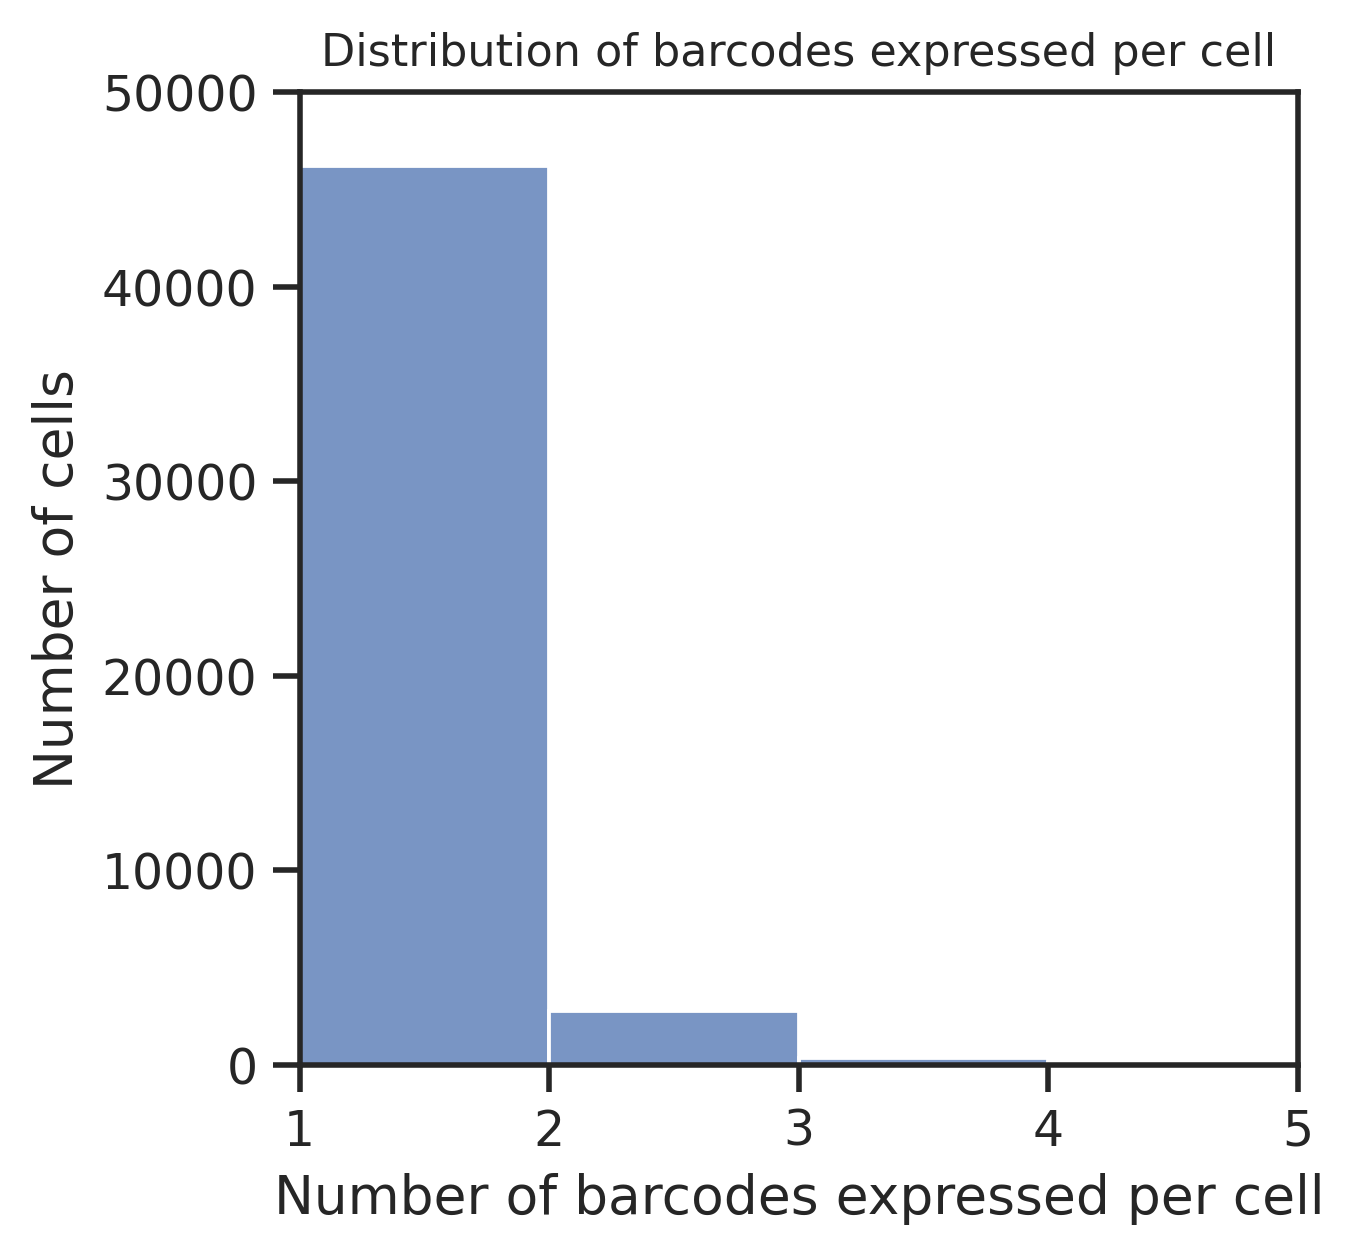

In [19]:
sb.set_theme(style="ticks")

data = np.array(np.sum(X > 5, axis=1)).flatten()

plt.figure(figsize=(4, 4))

ax = sb.histplot(
    data,
    binwidth=1
)

ax.set_xlim(1, 5)
ax.set_ylim(0, 50000)
ax.set_xlabel("Number of barcodes expressed per cell")
ax.set_ylabel("Number of cells")
ax.set_title(
    "Distribution of barcodes expressed per cell",
    fontsize=10
)

plt.savefig(
    "figure/pool_screen_cell_barcode_histogram_cutoff5.pdf",
    bbox_inches="tight"
)

In [19]:
pct_one_barcode = np.sum(data == 1) / np.sum(data > 0) * 100
print(f"% cells with only 1 barcode among cells with any barcode: {pct_one_barcode:.2f}%")

% cells with only 1 barcode among cells with any barcode: 93.40%


Now having decided on the threshold - look at which TF is the most dominant

In [29]:
# Convert to CSR for efficient row-wise operations
X = merged[:, antibody_capture].X.tocsr()

# Compute row-wise max and sum
row_max = X.max(axis=1).toarray().ravel()
row_sum = X.sum(axis=1).A1  

merged.obs['antibody_max_count'] = row_max
# antibody_calling based on which barcode has the highest count
merged.obs['antibody_calling'] = antibody_capture[np.argmax(np.array(merged[:,antibody_capture].X.todense()),axis=1)]
# TF calling from barcode calling
merged.obs.loc[select,'TF_calling'] = ['-'.join(tf.split('-')[:-2]) for tf in merged.obs['antibody_calling']]

# compute the fraction of the dominant barcode
with np.errstate(divide='ignore', invalid='ignore'):
    merged.obs['antibody_max_perc'] = np.divide(row_max, row_sum, out=np.zeros_like(row_max), where=row_sum != 0)

In [30]:
# set cut-off
cutoff = 6
# if max percentage =< 0.5, remove the antibody calling
merged.obs.loc[merged.obs['antibody_max_perc'] <= 0.5,'antibody_calling'] = np.nan
# if max count < cutoff, remove the antibody calling
merged.obs.loc[merged.obs['antibody_max_count'] < cutoff,'antibody_calling'] = np.nan

select = merged.obs['antibody_calling'].isna()
merged.obs.loc[select,'TF_calling'] = np.nan

In [40]:
sum(~select)/merged.shape[0] * 100

47.637851809305

In [31]:
# Create the Counter from the column
tf_counts = Counter(merged.obs['TF_calling'])

# Convert to DataFrame
df = pd.DataFrame(tf_counts.items(), columns=['TF_calling', 'count'])
df = df.loc[~df['TF_calling'].isna(),:]
#df = df.loc[~df['TF_calling'].isin(['MULTIHIT']),:]
df = df.sort_values(by='count', ascending=False)

In [32]:
df.head(10)

,TF_calling,count
0,MULTIHIT,4613
282,FOXR1,1547
494,WWTR1,1377
281,FOSL2,1367
31,ZBTB9,1049
451,EGR4,1015
167,ESRRB,640
63,IRF5,592
380,NR1I2,427
364,ZNF213,370


In [35]:
# only leave GEX genes for downstream
merged = merged[:,merged.var['feature_types']=='Gene Expression']

In [36]:
merged.write_h5ad('write/pool_tf_entire_data_raw_count_v2.h5ad')

/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1158: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1158: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


## Preprocessing - normalise and log

In [7]:
merged = sc.read('write/pool_tf_entire_data_raw_count_v2.h5ad')

In [37]:
sc.pp.normalize_per_cell(merged,counts_per_cell_after=1e4,key_n_counts='n_counts_GEX')

/tmp/ipykernel_2066897/1240904363.py:1: FutureWarning: Use sc.pp.normalize_total instead
  sc.pp.normalize_per_cell(merged,counts_per_cell_after=1e4,key_n_counts='n_counts_GEX')
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/scanpy/preprocessing/_simple.py:591: FutureWarning: Use sc.pp.normalize_total instead
  normalize_per_cell(


In [38]:
sc.pp.log1p(merged)

In [39]:
merged.write_h5ad('write/pool_tf_entire_data_normalised_log_v2.h5ad')

In [41]:
merged

AnnData object with n_obs × n_vars = 97496 × 36601
    obs: 'n_counts_GEX', 'n_genes', 'n_counts_antibody_capture', 'mito', 'file', 'sanger_sample_ID', 'HSC_days', 'FACS_sort', 'doublet_scores', 'predicted_doublets', 'batch', 'antibody_max_count', 'antibody_calling', 'TF_calling', 'antibody_max_perc'
    var: 'gene_ids', 'feature_types', 'genome', 'pattern', 'read', 'sequence'
    uns: 'log1p'